# Modelling

This notebook contains code for model training, validation and testing for day-ahead electricity price forecasting at 15min intervals.

## Data import

In this section, data is imported from database.

In [339]:
import sqlite3

# connect to database 

database_connection = sqlite3.connect("db_data_hoarder_ula.db")

cur = database_connection.cursor()

In [340]:
# import tables


# cur.execute("SELECT * FROM tge_quarters_processed")
# rows_tge_quarters = cur.fetchall()
# cols_tge_quarters = [desc[0] for desc in cur.description]


# cur.execute("SELECT * FROM weather_processed")
# rows_weather = cur.fetchall()
# cols_weather = [desc[0] for desc in cur.description]

# cur.execute("SELECT * from weather_forecast_processed")
# rows_weather_forecast = cur.fetchall()
# cols_weather_forecast = [desc[0] for desc in cur.description]

cur.execute("SELECT * from tge_rdnquarters_weather_forecast_kse")
rows_tge_rdnquarters_weather_forecast_kse = cur.fetchall()
cols_tge_rdnquarters_weather_forecast_kse = [desc[0] for desc in cur.description]


database_connection.close()

In [346]:
# convert to a pandas data frame

import pandas as pd

# tge_quarters = pd.DataFrame(rows_tge_quarters, columns = cols_tge_quarters)
# weather = pd.DataFrame(rows_weather, columns = cols_weather)
# weather_forecast = pd.DataFrame(rows_weather_forecast, columns = cols_weather_forecast)

tge_rdnquarters_weather_forecast_kse = pd.DataFrame(rows_tge_rdnquarters_weather_forecast_kse, columns = cols_tge_rdnquarters_weather_forecast_kse)

## Data transformation

Data is transformed into tensors and split into training, validation and testing datasets.

In [347]:
# save mean and std for target value (required to later transfer back to scale)

import numpy as np

price_ii_day_ahead_mean = np.mean(tge_rdnquarters_weather_forecast_kse["Price_ii_day_ahead"])
price_ii_day_ahead_std = np.std(tge_rdnquarters_weather_forecast_kse["Price_ii_day_ahead"])



In [348]:
tge_rdnquarters_weather_forecast_kse = tge_rdnquarters_weather_forecast_kse.drop(["Day_of_week", "Date_day_ahead"], axis = 1)

In [349]:
# normalise data


import sklearn

scaler = sklearn.preprocessing.StandardScaler()


tge_rdnquarters_weather_forecast_kse_normalised = tge_rdnquarters_weather_forecast_kse

for feature in tge_rdnquarters_weather_forecast_kse_normalised.columns:
  tge_rdnquarters_weather_forecast_kse_normalised[feature] = scaler.fit_transform(tge_rdnquarters_weather_forecast_kse_normalised[[feature]])

In [279]:
len(tge_rdnquarters_weather_forecast_kse)/96

292.0

In [281]:
205*96

19680

In [282]:
tge_rdnquarters_weather_forecast_kse_normalised

,Price_ii_previous_day,Price_ii_day_ahead,Temperatura_miasto_Białystok,Temperatura_miasto_Gdańsk,Temperatura_miasto_Gorzów Wielkopolski,Temperatura_miasto_Katowice,Temperatura_miasto_Kielce,Temperatura_miasto_Kraków,Temperatura_miasto_Lublin,Temperatura_miasto_Olsztyn,...,Prędkość_wiatru_miasto_Poznań,Prędkość_wiatru_miasto_Puławy,Prędkość_wiatru_miasto_Rzeszów,Prędkość_wiatru_miasto_Szczecin,Prędkość_wiatru_miasto_Toruń,Prędkość_wiatru_miasto_Warszawa,Prędkość_wiatru_miasto_Wrocław,Prędkość_wiatru_miasto_Łódź,load_fcst,load_actual
0,-0.355792,-0.202696,-0.897549,-0.651883,-0.950456,-0.986989,-1.003115,-1.012510,-0.960327,-0.867800,...,-0.535308,-0.509730,-0.085170,0.277107,-0.499254,-0.295758,0.375962,-0.257886,0.239699,0.449291
1,-0.487281,-0.202730,-0.897549,-0.651883,-0.950456,-0.986989,-1.003115,-1.012510,-0.960327,-0.867800,...,-0.535308,-0.509730,-0.085170,0.277107,-0.499254,-0.295758,0.375962,-0.257886,0.115558,0.358247
2,-0.501244,-0.202799,-0.897549,-0.651883,-0.950456,-0.986989,-1.003115,-1.012510,-0.960327,-0.867800,...,-0.535308,-0.509730,-0.085170,0.277107,-0.499254,-0.295758,0.375962,-0.257886,0.037970,0.265752
3,-0.515696,-0.202696,-0.897549,-0.651883,-0.950456,-0.986989,-1.003115,-1.012510,-0.960327,-0.867800,...,-0.535308,-0.509730,-0.085170,0.277107,-0.499254,-0.295758,0.375962,-0.257886,-0.070653,0.122299
4,-0.371149,-0.198038,-0.886006,-0.619807,-0.960481,-1.011688,-1.003115,-1.021827,-0.941868,-0.904226,...,-0.392780,-0.602425,0.330972,0.436145,-0.450478,-0.402157,0.381429,-0.046242,-0.163758,0.006859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28027,0.374742,0.801021,-0.122194,0.065948,0.294828,0.008492,-0.124367,0.322000,-0.118967,-0.160081,...,-0.096322,-0.040460,-0.125280,0.569737,-0.029784,-0.389640,-0.362112,-0.532451,1.325929,1.394095
28028,0.474159,0.832173,-0.174141,0.050463,-0.009253,-0.205209,-0.133704,-0.061063,-0.099536,-0.207956,...,-0.176138,0.121757,-0.090184,0.219853,-0.023687,-0.364604,-0.329308,-0.303647,1.325929,1.361335
28029,-0.125444,1.273367,-0.174141,0.050463,-0.009253,-0.205209,-0.133704,-0.061063,-0.099536,-0.207956,...,-0.176138,0.121757,-0.090184,0.219853,-0.023687,-0.364604,-0.329308,-0.303647,1.294894,1.293928
28030,-0.042114,0.926869,-0.174141,0.050463,-0.009253,-0.205209,-0.133704,-0.061063,-0.099536,-0.207956,...,-0.176138,0.121757,-0.090184,0.219853,-0.023687,-0.364604,-0.329308,-0.303647,1.232823,1.263201


In [350]:
# split into train and test using 65% of the data for training and 25% for testing

tge_rdnquarters_weather_forecast_kse_normalised_train = tge_rdnquarters_weather_forecast_kse.iloc[:19680]

tge_rdnquarters_weather_forecast_kse_normalised_test = tge_rdnquarters_weather_forecast_kse.iloc[19680: 28032]

In [367]:
len(tge_rdnquarters_weather_forecast_kse_normalised_train)/96

205.0

In [ ]:
tge_rdnquarters_weather_forecast_kse

In [351]:
# split into design matrix and response vector


X_train = tge_rdnquarters_weather_forecast_kse_normalised_train.drop(["Price_ii_day_ahead", "load_actual"], axis =1)
y_train = tge_rdnquarters_weather_forecast_kse_normalised_train["Price_ii_day_ahead"]

X_test = tge_rdnquarters_weather_forecast_kse_normalised_test.drop(["Price_ii_day_ahead", "load_actual"], axis =1)
y_test = tge_rdnquarters_weather_forecast_kse_normalised_test["Price_ii_day_ahead"]


In [353]:
# convert to numpy object 

X_train_numpy = X_train.to_numpy().reshape((205,96,53))
y_train_numpy = y_train.to_numpy().reshape((205,96,1))

X_test_numpy = X_test.to_numpy().reshape((87,96,53))
y_test_numpy = y_test.to_numpy().reshape((87,96,1))

In [354]:
# convert numpy array to tensor

import tensorflow as tf


X_train_tensor = tf.convert_to_tensor(X_train_numpy)
y_train_tensor = tf.convert_to_tensor(y_train_numpy)


X_test_tensor = tf.convert_to_tensor(X_test_numpy)
y_test_tensor = tf.convert_to_tensor(y_test_numpy)

## Model

In [388]:
# Model fitting
import keras

keras.utils.set_random_seed(42)

# Regularisation strength
reg = keras.regularizers.l2(0.001)

model_LSTM_sequences = keras.models.Sequential([
    keras.Input(shape=(96, 53)),

    keras.layers.LSTM(
        units=8,
        kernel_regularizer=reg,
        recurrent_regularizer=reg
    ),

    keras.layers.Dense(
        96,
        kernel_regularizer=reg
    )
])

optimiser = keras.optimizers.Adam(learning_rate=0.001)

model_LSTM_sequences.compile(
    optimizer=optimiser,
    loss="mean_squared_error",
    metrics=["mae", "root_mean_squared_error"]
)

history = model_LSTM_sequences.fit(
    X_train_tensor,
    y_train_tensor,
    epochs=150,
    batch_size=64
)

Epoch 1/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 269ms/step - loss: 0.9659 - mae: 0.5964 - root_mean_squared_error: 0.9511
Epoch 2/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.9525 - mae: 0.5896 - root_mean_squared_error: 0.9445
Epoch 3/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.9407 - mae: 0.5833 - root_mean_squared_error: 0.9387
Epoch 4/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.9302 - mae: 0.5776 - root_mean_squared_error: 0.9335
Epoch 5/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.9200 - mae: 0.5724 - root_mean_squared_error: 0.9285
Epoch 6/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.9100 - mae: 0.5675 - root_mean_squared_error: 0.9236
Epoch 7/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.9001 - mae: 0.5628 - root_mean_squared_error: 0.9187
Epoch 8/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.8900 - mae: 0.5582 - root_mean_squared_error: 0.9137
Epoch 9/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.8795 - mae: 0.5537 - root_mean_squa

In [389]:
# evaluate model

metrics = model_LSTM_sequences.evaluate(X_test_tensor, y_test_tensor, verbose = 0)

In [390]:
model_LSTM_sequences.evaluate(X_test_tensor, y_test_tensor, verbose = 0)

[0.7945543527603149, 0.6377631425857544, 0.8619322180747986]

In [391]:
# convert day-ahead price to original scale (non-normalised)

print(metrics[1] * price_ii_day_ahead_std) # MAE on original scale

184.56884795328995


In [377]:
predictions = model_LSTM_sequences.predict(X_test_tensor)
# predictions = predictions * price_ii_day_ahead_std + price_ii_day_ahead_mean

1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/stepWARNING:tensorflow:6 out of the last 10 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000001D35B593110> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


In [360]:
# plotting forecast

import matplotlib.pyplot as plt

plt.figure(figsize = (20,4))


plt.plot(tge_rdnquarters_weather_forecast_kse["Time_day_ahead"][tge_rdnquarters_weather_forecast_kse["Date_day_ahead"] == "2026-10-15"], y_test_tensor[103] * price_ii_day_ahead_std + price_ii_day_ahead_mean, label = "Kurs")
plt.plot(tge_rdnquarters_weather_forecast_kse["Time_day_ahead"][tge_rdnquarters_weather_forecast_kse["Date_day_ahead"] == "2026-10-15"], predictions[103] * price_ii_day_ahead_std + price_ii_day_ahead_mean, label = "Prognoza")
plt.xlabel("Czas")
plt.ylabel("Kurs (PLN/MWh)")
plt.title("Kurs i prognozoa TGE RDN 15min z dnia 15/10/2026")
plt.legend()
plt.xticks(rotation = 90)
plt.show()

KeyError: 'Time_day_ahead'

<Figure size 2000x400 with 0 Axes>

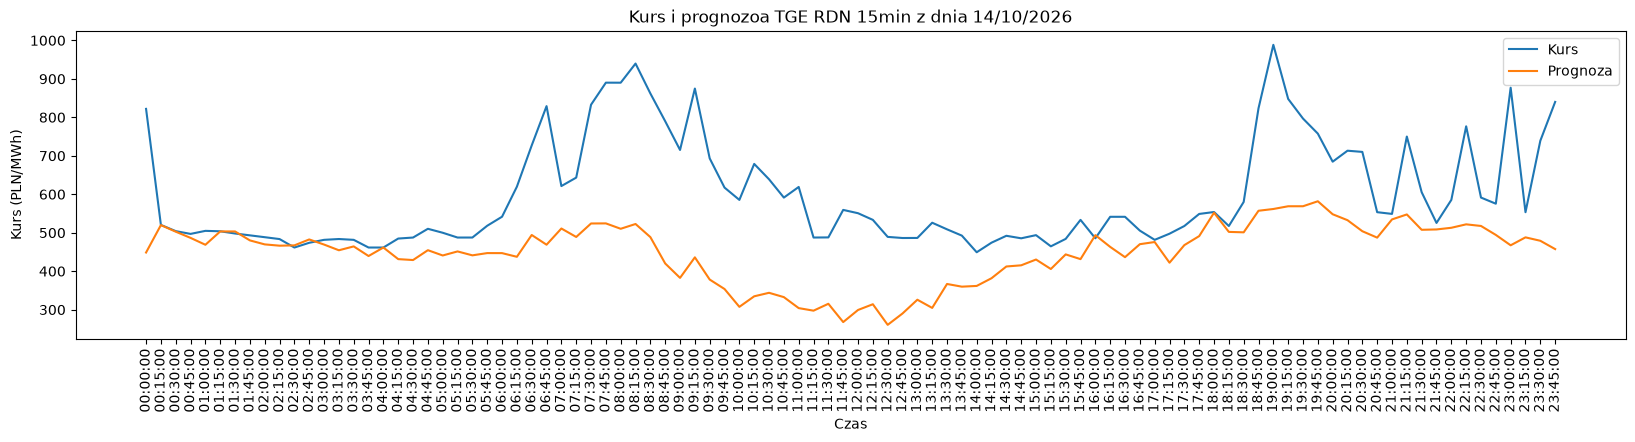

In [18]:
# plotting forecast 

import matplotlib.pyplot as plt

plt.figure(figsize = (20,4))


plt.plot(tge_rdnquarters_weather_forecast_kse["Time_previous_day"][tge_rdnquarters_weather_forecast_kse["Date_previous_day"] == "2026-10-14"], y_test_tensor[102] * price_ii_day_ahead_std + price_ii_day_ahead_mean, label = "Kurs")
plt.plot(tge_rdnquarters_weather_forecast_kse["Time_previous_day"][tge_rdnquarters_weather_forecast_kse["Date_previous_day"] == "2026-10-14"], predictions[102] * price_ii_day_ahead_std + price_ii_day_ahead_mean, label = "Prognoza")
plt.xlabel("Czas")
plt.ylabel("Kurs (PLN/MWh)")
plt.title("Kurs i prognozoa TGE RDN 15min z dnia 14/10/2026")
plt.legend()
plt.xticks(rotation = 90)
plt.show()

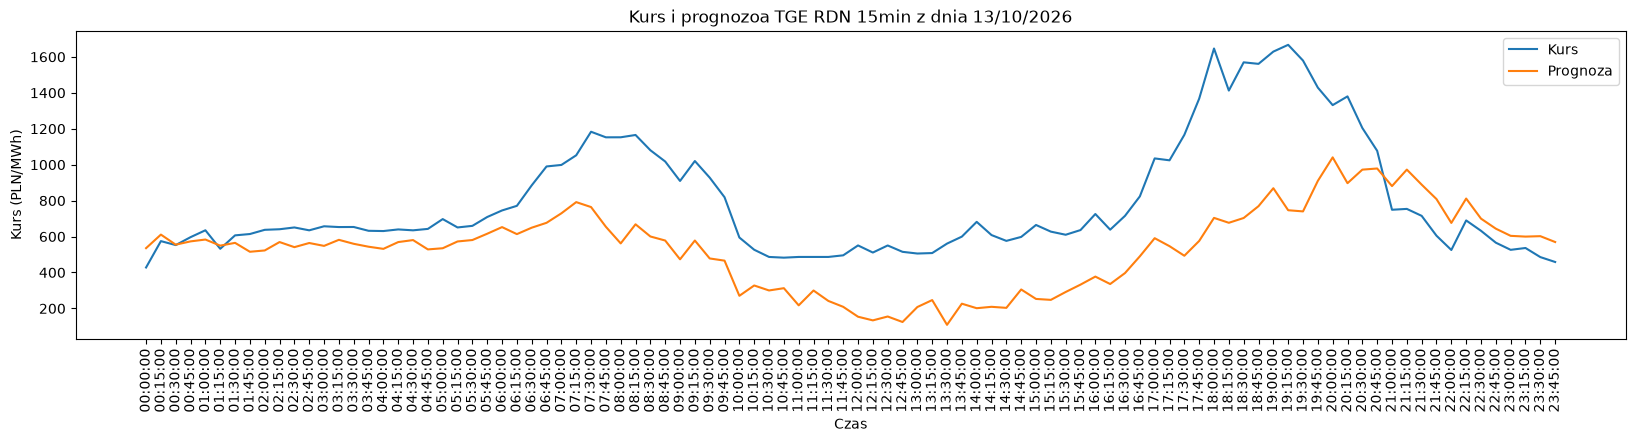

In [24]:
# plotting forecast

import matplotlib.pyplot as plt

plt.figure(figsize = (20,4))


plt.plot(tge_rdnquarters_weather_forecast_kse["Time_previous_day"][tge_rdnquarters_weather_forecast_kse["Date_previous_day"] == "2026-10-13"], y_test_tensor[101] * price_ii_day_ahead_std + price_ii_day_ahead_mean, label = "Kurs")
plt.plot(tge_rdnquarters_weather_forecast_kse["Time_previous_day"][tge_rdnquarters_weather_forecast_kse["Date_previous_day"] == "2026-10-13"], predictions[101] * price_ii_day_ahead_std + price_ii_day_ahead_mean, label = "Prognoza")
plt.xlabel("Czas")
plt.ylabel("Kurs (PLN/MWh)")
plt.title("Kurs i prognozoa TGE RDN 15min z dnia 13/10/2026")
plt.legend()
plt.xticks(rotation = 90)
plt.show()

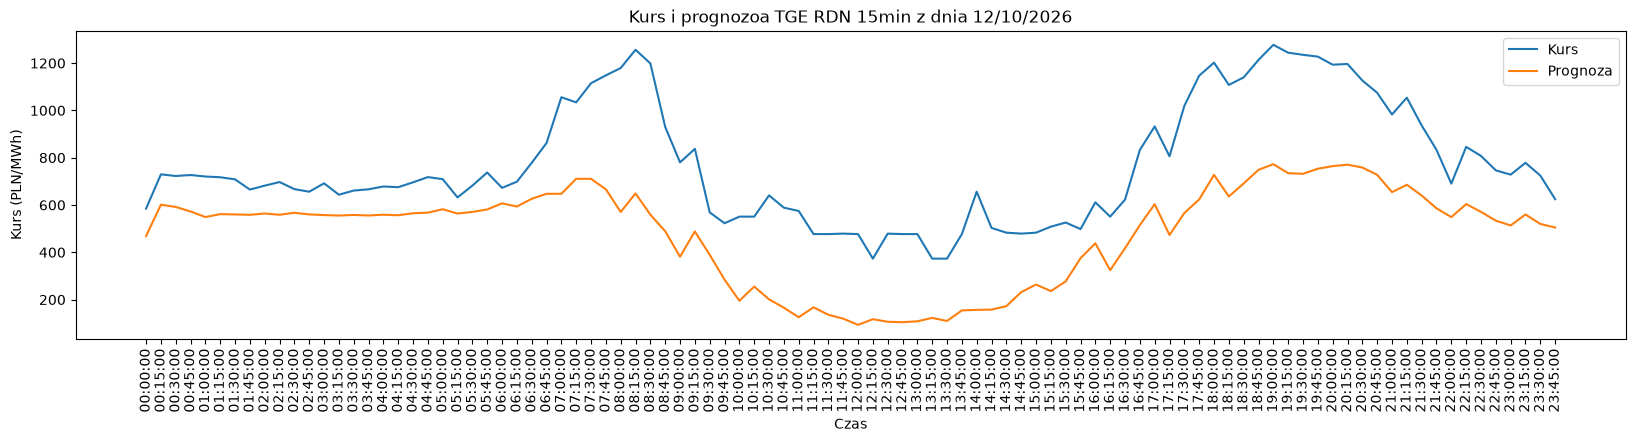

In [64]:
# plotting forecast

import matplotlib.pyplot as plt

plt.figure(figsize = (20,4))


plt.plot(tge_rdnquarters_weather_forecast["Time_previous_day"][tge_rdnquarters_weather_forecast["Date_previous_day"] == "2026-10-12"], y_test_tensor[100] * price_ii_day_ahead_std + price_ii_day_ahead_mean, label = "Kurs")
plt.plot(tge_rdnquarters_weather_forecast["Time_previous_day"][tge_rdnquarters_weather_forecast["Date_previous_day"] == "2026-10-12"], predictions[100] * price_ii_day_ahead_std + price_ii_day_ahead_mean, label = "Prognoza")
plt.xlabel("Czas")
plt.ylabel("Kurs (PLN/MWh)")
plt.title("Kurs i prognozoa TGE RDN 15min z dnia 12/10/2026")
plt.legend()
plt.xticks(rotation = 90)
plt.show()

In [44]:
# split the original design matrix into price and weather inputs

X_price_train = X_train_tensor[:, :, 0:1]  
X_weather_train = X_train_tensor[:, :, 1:6]

X_price_test = X_test_tensor[:,:,0:1]
X_weather_test = X_test_tensor[:,:,1:6]

In [50]:
X_weather_train

<tf.Tensor: shape=(222, 96, 5), dtype=float64, numpy=
array([[[ 2.33269364, -0.70313931,  0.18170753, -0.33813878,
         -0.83039488],
        [ 2.33269364, -0.70313931,  0.18170753, -0.33813878,
         -0.86171435],
        [ 2.33269364, -0.70313931,  0.18170753, -0.33813878,
         -0.90869355],
        ...,
        [ 2.00779411, -0.70313931,  0.09074265, -0.42534154,
         -0.50154047],
        [ 2.00779411, -0.70313931,  0.09074265, -0.42534154,
         -0.6111586 ],
        [ 2.00779411, -0.70313931,  0.09074265, -0.42534154,
         -0.72077674]],

       [[ 1.71500674, -0.70313931, -0.17292368, -0.12013186,
         -0.75209621],
        [ 1.71500674, -0.70313931, -0.17292368, -0.12013186,
         -0.78341568],
        [ 1.71500674, -0.70313931, -0.17292368, -0.12013186,
         -0.83039488],
        ...,
        [ 1.34796   , -0.70313931, -0.25700852, -0.42534154,
         -0.50154047],
        [ 1.34796   , -0.70313931, -0.25700852, -0.42534154,
         -0.61115

In [53]:
# model alternative

# model inputs 

price_input = keras.Input(shape = (96,1), name = "previous_day_price")
weather_input = keras.Input(shape = (96,5), name = "forecasts")

# price neurons

price_features = keras.layers.LSTM(64)(price_input)

# weather neurons 

weather_features = keras.layers.Flatten()(weather_input)
weather_features = keras.layers.Dense(
    16, activation="relu"
)(weather_features)



# combine neurons 

combined = keras.layers.Concatenate()([
    price_features,
    weather_features
])

# model output

x = keras.layers.Dense(64, activation="relu")(combined)
output = keras.layers.Dense(96)(x)

# final model architecture 

model = keras.Model(
    inputs=[price_input, weather_input],
    outputs=output
)

optimiser = keras.optimizers.Adam(learning_rate=0.001)

model.compile(
    optimizer = optimiser,
    loss = "mean_squared_error", 
    metrics = ["mae", "root_mean_squared_error"] 

)


# model fitting

history = model.fit(
    [X_price_train, X_weather_train],
    y_train_tensor,
    epochs=300,
    batch_size=128
)


Epoch 1/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 786ms/step - loss: 0.9094 - mae: 0.6144 - root_mean_squared_error: 0.9536
Epoch 2/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.8630 - mae: 0.5849 - root_mean_squared_error: 0.9290
Epoch 3/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 0.8392 - mae: 0.5705 - root_mean_squared_error: 0.9161
Epoch 4/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 0.8217 - mae: 0.5622 - root_mean_squared_error: 0.9065
Epoch 5/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.8034 - mae: 0.5555 - root_mean_squared_error: 0.8963
Epoch 6/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.7825 - mae: 0.5485 - root_mean_squared_error: 0.8846
Epoch 7/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.7588 - mae: 0.5409 - root_mean_squared_error: 0.8711
Epoch 8/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - loss: 0.7340 - mae: 0.5339 - root_mean_squared_error: 0.8567 
Epoch 9/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.7090 - mae: 0.5274 - root_mean_squ

In [54]:

model.evaluate([X_price_test, X_weather_test], y_test_tensor, verbose = 0)

[0.7371116280555725, 0.5923773050308228, 0.8585520386695862]

In [161]:
print(X_price_train.shape)

(244, 96, 1)
